# NB6.2 — Zero-cost NAS on EuroSAT
____________________________________________________________________________________________________

In NB2–NB4 we designed the CNN **by hand**: one factor at a time, ~30 full trainings. Here we let a **search algorithm** design it, using the zero-cost proxies validated on NAS-Bench-201 in NB6.1: an architecture is judged **at initialization**, in a fraction of a second, without training it.

a. The search space: the knobs of Task 2 (depth, kernel size of every block, width, BatchNorm, downsampling) + skip connections

b. The proxies (same code as NB6.1)

c. **Do the proxies predict the accuracy on EuroSAT?** 50 random architectures, each trained for a short budget, vs their proxy scores

d. **Search**: score 1000 random architectures, train only the best ones (top-k) and compare with random architectures and with our hand-designed CNN

e. The NAS winner trained with the full recipe of NB4, compared with the hand-designed CNN (accuracy, size, latency, GPU time)

f. Checkpoint loading

## 0. Setup

In [1]:
import os
import json
import time
import random

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader, Subset
import matplotlib.pyplot as plt

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

SEED = 42

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(SEED)

ON_KAGGLE = os.path.exists("/kaggle/input")

def find_path(name, search_roots):
    # walk the search folders and return the first file / folder called `name`
    for search_root in search_roots:
        for root, dirs, files in os.walk(search_root):
            if name in dirs or name in files:
                return os.path.join(root, name)
    return None

SEARCH_ROOTS = ["/kaggle/input"] if ON_KAGGLE else ["..", "../.."]
DATA_ROOT = find_path("EuroSAT_RGB", SEARCH_ROOTS)
SPLITS_FILE = find_path("splits.json", SEARCH_ROOTS)

OUT_DIR = "/kaggle/working" if ON_KAGGLE else "."
CKPT_DIR = os.path.join(OUT_DIR, "checkpoints")
RES_DIR = os.path.join(OUT_DIR, "results")
os.makedirs(CKPT_DIR, exist_ok=True)
os.makedirs(RES_DIR, exist_ok=True)

NUM_WORKERS = 4 if ON_KAGGLE else 0

print("DATA_ROOT  :", DATA_ROOT)
print("SPLITS_FILE:", SPLITS_FILE)

from scipy.stats import kendalltau, spearmanr

Using device: cuda:0
DATA_ROOT  : /kaggle/input/datasets/waseemalastal/eurosat-rgb-dataset/EuroSAT_RGB
SPLITS_FILE: /kaggle/input/notebooks/emilioyared/aide500-nb0-setup-data-run-1010-1100/splits.json


In [2]:
with open(SPLITS_FILE) as f:
    splits = json.load(f)

classes = splits["classes"]
num_classes = len(classes)
MEAN, STD = splits["mean"], splits["std"]

# plain transformation: validation, test (and training without augmentation)
plain_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)])

dataset = torchvision.datasets.ImageFolder(root=DATA_ROOT, transform=plain_transform)
valset = Subset(dataset, splits["val"])
testset = Subset(dataset, splits["test"])

# a fixed subset of the training images WITHOUT augmentation (same size as the validation set),
# used to measure the real train accuracy -> generalization gap (see section c)
rng = np.random.RandomState(0)
train_eval_set = Subset(dataset, sorted(rng.choice(splits["train"], len(splits["val"]), replace=False).tolist()))
print("train: %d | val: %d | test: %d | clean train subset: %d" % (len(splits["train"]), len(valset), len(testset), len(train_eval_set)))

BATCH_SIZE = 64
valloader = DataLoader(valset, batch_size=256, shuffle=False, num_workers=NUM_WORKERS)
testloader = DataLoader(testset, batch_size=256, shuffle=False, num_workers=NUM_WORKERS)
train_eval_loader = DataLoader(train_eval_set, batch_size=256, shuffle=False, num_workers=NUM_WORKERS)


def make_trainloader(augmentations):
    # augmentations: list of transforms applied to the PIL image, before ToTensor / Normalize
    train_transform = transforms.Compose(augmentations + [
        transforms.ToTensor(),
        transforms.Normalize(MEAN, STD)])
    train_dataset = torchvision.datasets.ImageFolder(root=DATA_ROOT, transform=train_transform)
    trainset = Subset(train_dataset, splits["train"])
    return DataLoader(trainset, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS)

train: 18900 | val: 4050 | test: 4050 | clean train subset: 4050


**Training recipe of NB4** (architecture of NB2, optimizer / scheduler of NB3, augmentation of NB4): used at the end to train the NAS winner exactly like the hand-designed CNN.

In [3]:
RECIPE_FILE = find_path("NB4_best_recipe.json", SEARCH_ROOTS)
if RECIPE_FILE is not None:
    with open(RECIPE_FILE) as f:
        best4 = json.load(f)
else:
    best4 = {"name": "flips_crop_mixup", "arch": dict(n_blocks=5, kernel_size=3, padding="same", downsample="pool", use_bn=True, n_fc=2),
             "recipe": {"optimizer": "Adam", "lr": 1e-3, "scheduler": "StepLR"}, "n_epochs": 25,
             "augmentations": ["flips", "crop"], "mix": "mixup", "test_acc": None}
HAND_ARCH, RECIPE, n_epochs = best4["arch"], best4["recipe"], best4["n_epochs"]
print("hand-designed CNN (NB2):", HAND_ARCH)
print("recipe (NB3/NB4)       :", RECIPE, "| epochs:", n_epochs, "| augmentations:", best4["augmentations"], "| mix:", best4["mix"])
print("test accuracy in NB4   :", best4["test_acc"])

hand-designed CNN (NB2): {'n_blocks': 5, 'n_fc': 2, 'kernel_size': 3, 'padding': 'same', 'downsample': 'pool', 'use_bn': True}
recipe (NB3/NB4)       : {'optimizer': 'Adam', 'lr': 0.001, 'scheduler': 'StepLR'} | epochs: 25 | augmentations: ['flips', 'crop'] | mix: mixup
test accuracy in NB4   : 97.03703703703704


## a. The search space

We turn the knobs of Task 2 into a search space. A network is a stack of `n_blocks` blocks followed by the same classifier as before (flatten → 256 → 10):

| knob | choices |
|---|---|
| number of blocks | 2, 3, 4, 5 |
| kernel size **of each block** | 3, 5, 7 |
| width (channels of the 1st block, doubled at every block, max 256) | 16, 32, 64 |
| BatchNorm | yes / no |
| downsampling | max-pooling / stride-2 convolution |
| skip connection (residual, with a 1×1 convolution) | yes / no |

Each block: `Conv(k×k, padding k//2) [→ BN]` `(+ shortcut)` `→ ReLU [→ MaxPool]`. With padding $k/2$ the convolution keeps the size, and the pooling (or the stride 2) halves it: after $n$ blocks the maps are $64 / 2^n$.

Number of architectures: $(3^2 + 3^3 + 3^4 + 3^5) \times 3 \times 2 \times 2 \times 2 = 360 \times 24 = 8{,}640$. Our hand-designed CNN of NB2 is one of them (5 blocks, all kernels 3, width 32, BN, max-pooling, no skip).

In [4]:
class Block(nn.Module):
    def __init__(self, c_in, c_out, k, use_bn, downsample, skip):
        super(Block, self).__init__()
        s = 2 if downsample == "stride" else 1
        layers = [nn.Conv2d(c_in, c_out, k, stride=s, padding=k // 2, bias=not use_bn)]   # h_out = (h + 2(k//2) - k) / s + 1
        if use_bn:
            layers.append(nn.BatchNorm2d(c_out))
        self.conv = nn.Sequential(*layers)
        self.shortcut = None
        if skip:
            # 1x1 convolution so that the shortcut has the same channels / size as the main branch
            sc = [nn.Conv2d(c_in, c_out, 1, stride=s, bias=not use_bn)]
            if use_bn:
                sc.append(nn.BatchNorm2d(c_out))
            self.shortcut = nn.Sequential(*sc)
        self.relu = nn.ReLU()
        self.pool = nn.MaxPool2d(2, 2) if downsample == "pool" else None

    def forward(self, x):
        out = self.conv(x)
        if self.shortcut is not None:
            out = out + self.shortcut(x)           # residual connection
        out = self.relu(out)
        if self.pool is not None:
            out = self.pool(out)
        return out


class SearchNet(nn.Module):
    def __init__(self, kernels=(3, 3, 3), width=32, use_bn=False, downsample="pool", skip=False, num_classes=10):
        super(SearchNet, self).__init__()
        n_blocks = len(kernels)
        channels = [3] + [min(width * 2 ** i, 256) for i in range(n_blocks)]
        self.features = nn.Sequential(*[Block(channels[i], channels[i + 1], kernels[i], use_bn, downsample, skip) for i in range(n_blocks)])
        h = 64 // 2 ** n_blocks                                  # every block halves the size
        self.flat_features = channels[-1] * h * h
        self.classifier = nn.Sequential(
            nn.Linear(self.flat_features, 256),
            nn.ReLU(),
            nn.Linear(256, num_classes))

    def forward(self, x):
        x = self.features(x)                       # [B, C, h, h]
        x = x.view(-1, self.flat_features)         # [B, C*h*h]
        return self.classifier(x)                  # [B, 10]


def arch_name(a):
    return "k%s_w%d_%s_%s_%s" % ("".join(str(k) for k in a["kernels"]), a["width"], "bn" if a["use_bn"] else "nobn",
                                 a["downsample"], "skip" if a["skip"] else "noskip")


def sample_arch(rng):
    # the number of blocks is drawn first (uniform), so that shallow networks are not rare
    n_blocks = rng.choice([2, 3, 4, 5])
    return {"kernels": [int(k) for k in rng.choice([3, 5, 7], n_blocks)], "width": int(rng.choice([16, 32, 64])),
            "use_bn": bool(rng.rand() < 0.5), "downsample": str(rng.choice(["pool", "stride"])), "skip": bool(rng.rand() < 0.5)}


# the hand-designed CNN of NB2 inside this search space
HAND = {"kernels": [HAND_ARCH["kernel_size"]] * HAND_ARCH["n_blocks"], "width": 32, "use_bn": HAND_ARCH["use_bn"],
        "downsample": HAND_ARCH["downsample"], "skip": False}
hand_net = SearchNet(**HAND)
print(arch_name(HAND))
print(hand_net)
print("parameters:", sum(p.numel() for p in hand_net.parameters()))

k33333_w32_bn_pool_noskip
SearchNet(
  (features): Sequential(
    (0): Block(
      (conv): Sequential(
        (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      )
      (relu): ReLU()
      (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1): Block(
      (conv): Sequential(
        (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      )
      (relu): ReLU()
      (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (2): Block(
      (conv): Sequential(
        (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      )
  

Check: the hand-designed CNN written as a `SearchNet` must have exactly the same number of parameters as the `ConfigNet` of NB2–NB4 (1,244,202).

In [5]:
class ConfigNet(nn.Module):
    def __init__(self, n_blocks=3, kernel_size=3, padding="same", downsample="pool", use_bn=False, n_fc=2, num_classes=10):
        super(ConfigNet, self).__init__()
        channels = [3] + [min(32 * 2 ** i, 256) for i in range(n_blocks)]  # e.g. n_blocks=3 -> [3, 32, 64, 128]
        p = kernel_size // 2 if padding == "same" else 0
        s = 2 if downsample == "stride" else 1

        blocks = []
        h = 64  # input images are 64x64
        for i in range(n_blocks):
            layers = []
            # with BatchNorm, the conv bias is useless (BN subtracts the mean and adds its own bias beta)
            layers.append(nn.Conv2d(channels[i], channels[i + 1], kernel_size, stride=s, padding=p, bias=not use_bn))
            h = (h + 2 * p - kernel_size) // s + 1           # size after the convolution
            if use_bn:
                layers.append(nn.BatchNorm2d(channels[i + 1]))
            layers.append(nn.ReLU())
            if downsample == "pool":
                layers.append(nn.MaxPool2d(2, 2))
                h = (h - 2) // 2 + 1                         # size after the pooling
            blocks.append(nn.Sequential(*layers))
        self.features = nn.Sequential(*blocks)

        assert h >= 1, "the feature maps disappear (size %d): too many blocks for this padding / kernel" % h
        self.flat_features = channels[-1] * h * h            # number of inputs of the first fc layer
        self.out_size = h

        # fully connected layers: 1 -> [flat, 10] | 2 -> [flat, 256, 10] | 3 -> [flat, 256, 128, 10]
        fc_sizes = [self.flat_features] + [256, 128][:n_fc - 1] + [num_classes]
        fc_layers = []
        for i in range(n_fc):
            fc_layers.append(nn.Linear(fc_sizes[i], fc_sizes[i + 1]))
            if i < n_fc - 1:                                 # no ReLU after the last layer (we want raw scores)
                fc_layers.append(nn.ReLU())
        self.classifier = nn.Sequential(*fc_layers)

    def forward(self, x):
        x = self.features(x)                     # [B, C, h, h]
        x = x.view(-1, self.flat_features)       # [B, C*h*h] flatten
        x = self.classifier(x)                   # [B, 10]
        return x


# check: the default configuration is exactly the baseline of NB1
net = ConfigNet()
print(net)
print("last feature maps: %dx%d | flat features: %d" % (net.out_size, net.out_size, net.flat_features))
print("parameters:", sum(p.numel() for p in net.parameters()))

ConfigNet(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU()
      (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU()
      (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (2): Sequential(
      (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU()
      (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
  )
  (classifier): Sequential(
    (0): Linear(in_features=8192, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=10, bias=True)
  )
)
last feature maps: 8x8 | flat features: 8192
parameters: 2193226


In [6]:
print("ConfigNet:", sum(p.numel() for p in ConfigNet(**HAND_ARCH).parameters()), "| SearchNet:", sum(p.numel() for p in SearchNet(**HAND).parameters()))

ConfigNet: 1244202 | SearchNet: 1244202


## b. The zero-cost proxies

Exactly the functions of NB6.1, where we checked them against the published results on NAS-Bench-201. They only need **one mini-batch of EuroSAT training images** (128 for NASWOT, 64 for the gradient proxies) — no labels for NASWOT and no data at all for SynFlow.

In [7]:
def naswot_score(net, inputs):
    B = inputs.size(0)
    K = torch.zeros(B, B, dtype=torch.float64, device=inputs.device)

    def hook(module, inp, out):
        x = (inp[0].view(B, -1) > 0).double()                # binary code of this ReLU layer
        K.add_(x @ x.t() + (1 - x) @ (1 - x).t())            # = units - Hamming distance

    handles = [m.register_forward_hook(hook) for m in net.modules() if isinstance(m, nn.ReLU)]
    with torch.no_grad():
        net(inputs)
    for h in handles:
        h.remove()
    sign, logdet = torch.linalg.slogdet(K)
    return logdet.item() if sign > 0 else -1e6               # singular kernel (e.g. a cell made of 'none' only)

In [8]:
def gradient_proxies(net, inputs, labels):
    # grad-norm and SNIP, from the gradient of the cross-entropy on one mini-batch
    net.train()
    net.zero_grad()
    loss = nn.CrossEntropyLoss()(net(inputs), labels)
    loss.backward()
    grad_norm, snip = 0.0, 0.0
    for m in net.modules():
        if isinstance(m, (nn.Conv2d, nn.Linear)) and m.weight.grad is not None:
            grad_norm += m.weight.grad.norm().item()
            snip += (m.weight * m.weight.grad).abs().sum().item()
    return grad_norm, snip


def synflow_score(net, input_shape):
    net = net.double()
    net.eval()
    with torch.no_grad():
        for p in net.state_dict().values():
            p.abs_()                                          # all weights positive
    net.zero_grad()
    x = torch.ones((1,) + tuple(input_shape), dtype=torch.float64, device=device)
    torch.sum(net(x)).backward()
    score = 0.0
    for m in net.modules():
        if isinstance(m, (nn.Conv2d, nn.Linear)) and m.weight.grad is not None:
            score += (m.weight * m.weight.grad).abs().sum().item()
    return score


def n_params(net):
    return sum(p.numel() for p in net.parameters())

In [9]:
score_loader = DataLoader(Subset(dataset, splits["train"]), batch_size=128, shuffle=True, generator=torch.Generator().manual_seed(0))
x128, y128 = next(iter(score_loader))
x128, y128 = x128.to(device), y128.to(device)
x64, y64 = x128[:64], y128[:64]


def all_proxies(arch, seed=0):
    set_seed(seed)
    net = SearchNet(**arch).to(device)
    scores = {"params": n_params(net), "naswot": naswot_score(net, x128)}
    scores["grad_norm"], scores["snip"] = gradient_proxies(net, x64, y64)
    set_seed(seed)
    scores["synflow"] = synflow_score(SearchNet(**arch).to(device), (3, 64, 64))
    return scores

start = time.time()
print(all_proxies(HAND))
print("%.2f s" % (time.time() - start))

{'params': 1244202, 'naswot': 1430.411180079535, 'grad_norm': 12.496393978595734, 'snip': 55.58140468597412, 'synflow': 953324490.1851188}
3.05 s


## c. Do the proxies predict the accuracy on EuroSAT?

On NAS-Bench-201 the true accuracy of every architecture is known. On EuroSAT nobody has trained our 8,640 architectures, so we build a small "benchmark" ourselves: **50 random architectures** (+ the hand-designed one), each trained with a **short budget** (5 epochs, Adam lr 1e-3, no augmentation). Its best validation accuracy is our "ground truth".

A short training is itself only an approximation of the final accuracy (some architectures learn faster than others), but it keeps the experiment affordable (~1 min per architecture).

Training helpers of NB4 (`train_one_epoch` with the optional MixUp / CutMix, `evaluate`, `measure_latency`).

In [10]:
def train_one_epoch(net, loader, criterion, optimizer, batch_scheduler=None, mix=None):
    net.train()
    running_loss, correct, total = 0.0, 0.0, 0
    for i, data in enumerate(loader, 0):
        inputs, labels = data[0].to(device), data[1].to(device)
        if mix == "mixup":
            inputs, labels_a, labels_b, lam = mixup_batch(inputs, labels)
        elif mix == "cutmix":
            inputs, labels_a, labels_b, lam = cutmix_batch(inputs, labels)

        optimizer.zero_grad()
        outputs = net(inputs)
        if mix is None:
            loss = criterion(outputs, labels)
        else:
            loss = lam * criterion(outputs, labels_a) + (1 - lam) * criterion(outputs, labels_b)
        loss.backward()
        optimizer.step()
        if batch_scheduler is not None:
            batch_scheduler.step()

        running_loss += loss.item() * labels.size(0)
        _, predicted = torch.max(outputs, 1)
        if mix is None:
            correct += (predicted == labels).sum().item()
        else:
            correct += lam * (predicted == labels_a).sum().item() + (1 - lam) * (predicted == labels_b).sum().item()
        total += labels.size(0)
    return running_loss / total, 100.0 * correct / total

In [11]:
def evaluate(net, loader, criterion):
    net.eval()
    running_loss, total = 0.0, 0
    all_preds, all_labels = [], []
    with torch.no_grad():
        for data in loader:
            images, labels = data[0].to(device), data[1].to(device)
            outputs = net(images)
            running_loss += criterion(outputs, labels).item() * labels.size(0)
            _, predicted = torch.max(outputs, 1)
            all_preds.append(predicted.cpu())
            all_labels.append(labels.cpu())
            total += labels.size(0)
    all_preds = torch.cat(all_preds).numpy()
    all_labels = torch.cat(all_labels).numpy()
    acc = 100.0 * (all_preds == all_labels).mean()
    per_class_acc = [100.0 * (all_preds[all_labels == c] == c).mean() for c in range(num_classes)]
    return running_loss / total, acc, per_class_acc, all_preds, all_labels


def measure_latency(net, n_runs=100):
    net.eval()
    x = torch.randn(1, 3, 64, 64).to(device)
    with torch.no_grad():
        for _ in range(10):  # warm-up
            net(x)
        if device.type == "cuda": torch.cuda.synchronize()  # wait for the GPU to finish before reading the time
        start = time.time()
        for _ in range(n_runs):
            net(x)
        if device.type == "cuda": torch.cuda.synchronize()
    return (time.time() - start) / n_runs * 1000  # milliseconds per image

In [12]:
SHORT_EPOCHS = 5
criterion = nn.CrossEntropyLoss()
plain_trainloader = make_trainloader([])         # no augmentation


def short_train(arch):
    set_seed(SEED)
    net = SearchNet(**arch).to(device)
    optimizer = optim.Adam(net.parameters(), lr=1e-3)
    start = time.time()
    best_val_acc = 0.0
    for epoch in range(SHORT_EPOCHS):
        train_one_epoch(net, plain_trainloader, criterion, optimizer)
        _, val_acc, _, _, _ = evaluate(net, valloader, criterion)
        best_val_acc = max(best_val_acc, val_acc)
    return best_val_acc, time.time() - start


rng = np.random.RandomState(SEED)
study_archs = [sample_arch(rng) for _ in range(50)] + [HAND]
study = []
for i, arch in enumerate(study_archs):
    scores = all_proxies(arch)
    val_acc, train_time = short_train(arch)
    study.append({"arch": arch, "name": arch_name(arch), "short_val_acc": val_acc, "train_time_s": train_time, **scores})
    print('[%2d/%d] %-34s params %9d | naswot %8.1f | short val acc %.2f %% | %.0f s' %
          (i + 1, len(study_archs), arch_name(arch), scores["params"], scores["naswot"], val_acc, train_time))

[ 1/51] k3773_w16_bn_pool_skip             params    738474 | naswot   1344.9 | short val acc 89.26 % | 121 s
[ 2/51] k3753_w32_nobn_stride_skip         params   1696394 | naswot   1195.3 | short val acc 83.93 % | 52 s
[ 3/51] k33553_w16_bn_pool_skip            params    866474 | naswot   1351.6 | short val acc 91.83 % | 52 s
[ 4/51] k75575_w64_bn_stride_noskip        params   6149962 | naswot   1334.8 | short val acc 74.74 % | 64 s
[ 5/51] k3773_w16_bn_stride_noskip         params    727194 | naswot   1163.7 | short val acc 80.79 % | 50 s
[ 6/51] k553_w32_bn_stride_skip            params   2238538 | naswot   1252.9 | short val acc 84.10 % | 50 s
[ 7/51] k73775_w16_bn_stride_noskip        params   1593882 | naswot   1170.4 | short val acc 74.91 % | 52 s
[ 8/51] k555_w32_bn_stride_noskip          params   2358826 | naswot   1245.4 | short val acc 81.73 % | 51 s
[ 9/51] k555_w64_nobn_stride_noskip        params   5226378 | naswot   1302.1 | short val acc 81.01 % | 52 s
[10/51] k35335_w64

proxy       Spearman rho  Kendall tau
naswot             0.433        0.324
synflow            0.091        0.069
snip               0.510        0.375
grad_norm          0.557        0.402
params            -0.131       -0.082


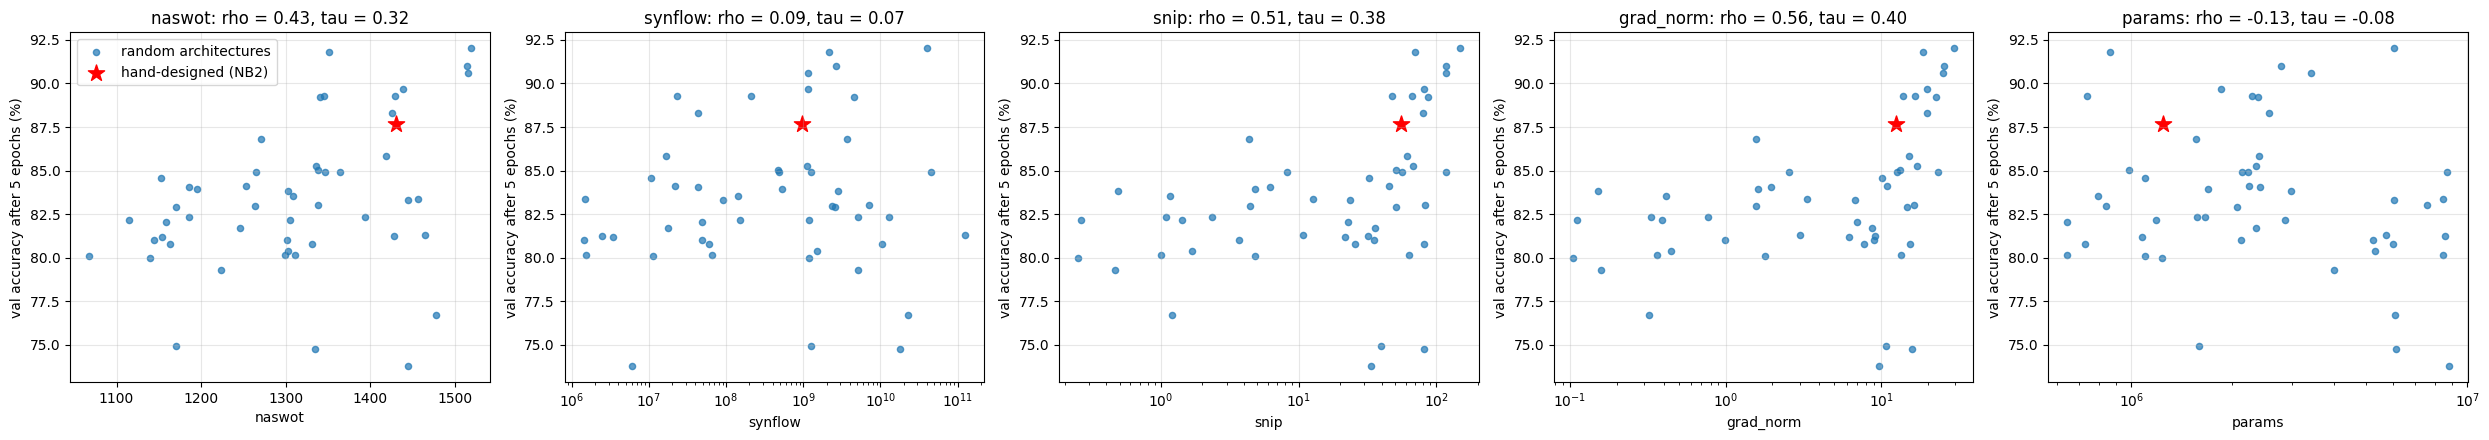

In [13]:
PROXIES = ["naswot", "synflow", "snip", "grad_norm", "params"]
acc = np.array([s["short_val_acc"] for s in study])
print('%-10s %13s %12s' % ('proxy', 'Spearman rho', 'Kendall tau'))
eurosat_corr = {}
for p in PROXIES:
    values = np.array([s[p] for s in study], dtype=float)
    eurosat_corr[p] = (spearmanr(values, acc)[0], kendalltau(values, acc)[0])
    print('%-10s %13.3f %12.3f' % (p, eurosat_corr[p][0], eurosat_corr[p][1]))

fig, axes = plt.subplots(1, 5, figsize=(25, 4.5))
for ax, p in zip(axes, PROXIES):
    values = np.array([s[p] for s in study], dtype=float)
    ax.scatter(values[:-1], acc[:-1], s=20, alpha=0.7, label="random architectures")
    ax.scatter(values[-1:], acc[-1:], s=150, marker="*", color="red", label="hand-designed (NB2)")
    if p != "naswot":
        ax.set_xscale("log")
    ax.set_xlabel(p); ax.set_ylabel("val accuracy after %d epochs (%%)" % SHORT_EPOCHS)
    ax.set_title("%s: rho = %.2f, tau = %.2f" % (p, eurosat_corr[p][0], eurosat_corr[p][1])); ax.grid(alpha=0.3)
axes[0].legend()
plt.tight_layout()
plt.show()

with open(os.path.join(RES_DIR, "NB6_2_correlation_study.json"), "w") as f:
    json.dump({"study": study, "correlations": eurosat_corr}, f, indent=2)

## d. Search: score 1000 architectures, train only the best ones

**Zero-cost NAS** (Algorithm 1 of the NASWOT paper, with a small extension):
1. sample 1000 random architectures and compute their proxies at initialization (a few minutes for all of them);
2. keep the **top-3** architectures by NASWOT and the top-3 by SynFlow;
3. train only these 6 with the short budget and keep the best one (on the validation set).

**Baseline:** 3 random architectures with the same short training (random search with the same training budget).

In [14]:
rng = np.random.RandomState(1)
candidates = [sample_arch(rng) for _ in range(1000)]
start = time.time()
cand_scores = [all_proxies(arch) for arch in candidates]
scoring_time = time.time() - start
print("1000 architectures scored with the 5 proxies in %.0f s (%.0f ms per architecture)" % (scoring_time, scoring_time))

TOP_K = 3
top_naswot = np.argsort([-s["naswot"] for s in cand_scores])[:TOP_K]
top_synflow = np.argsort([-s["synflow"] for s in cand_scores])[:TOP_K]
random_pick = np.random.RandomState(2).choice(len(candidates), TOP_K, replace=False)

search_results = []
trained = {}                                     # an architecture chosen by 2 proxies is trained only once
for method, idx_list in [("NASWOT top-3", top_naswot), ("SynFlow top-3", top_synflow), ("random", random_pick)]:
    for i in idx_list:
        if i not in trained:
            trained[i] = short_train(candidates[i])
        val_acc, train_time = trained[i]
        search_results.append({"method": method, "arch": candidates[i], "name": arch_name(candidates[i]),
                               "short_val_acc": val_acc, "train_time_s": train_time, **cand_scores[i]})
        print('%-14s %-34s params %9d | naswot %8.1f | short val acc %.2f %%' %
              (method, arch_name(candidates[i]), cand_scores[i]["params"], cand_scores[i]["naswot"], val_acc))
hand_short = study[-1]["short_val_acc"]
print("\nhand-designed CNN with the same short training: %.2f %%" % hand_short)

1000 architectures scored with the 5 proxies in 153 s (153 ms per architecture)
NASWOT top-3   k53333_w64_bn_pool_skip            params   1994122 | naswot   1520.9 | short val acc 92.15 %
NASWOT top-3   k5337_w64_bn_pool_skip             params   4745610 | naswot   1519.6 | short val acc 89.19 %
NASWOT top-3   k5335_w64_bn_pool_skip             params   3172746 | naswot   1519.5 | short val acc 90.94 %
SynFlow top-3  k75775_w64_bn_pool_skip            params   7110538 | naswot   1515.7 | short val acc 91.63 %
SynFlow top-3  k77735_w64_bn_pool_skip            params   4685706 | naswot   1514.2 | short val acc 90.64 %
SynFlow top-3  k77535_w64_nobn_pool_skip          params   3897354 | naswot   1464.5 | short val acc 81.60 %
random         k7373_w64_bn_pool_noskip           params   3331402 | naswot   1500.1 | short val acc 84.77 %
random         k53_w64_bn_stride_noskip           params   8470346 | naswot   1303.7 | short val acc 80.62 %
random         k37777_w64_bn_stride_skip        

method             mean acc     best acc
NASWOT top-3         90.76%       92.15%
SynFlow top-3        87.96%       91.63%
random               83.32%       84.77%
hand-designed        87.65%       87.65%


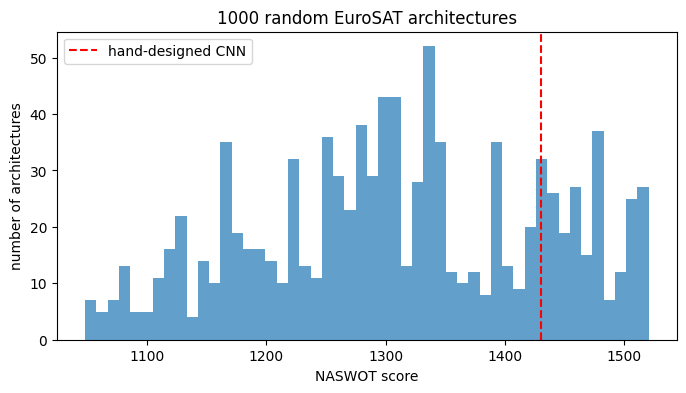

NAS winner: k53333_w64_bn_pool_skip (NASWOT top-3, short val acc 92.15 %)


In [15]:
print('%-14s %12s %12s' % ('method', 'mean acc', 'best acc'))
for method in ["NASWOT top-3", "SynFlow top-3", "random"]:
    a = [r["short_val_acc"] for r in search_results if r["method"] == method]
    print('%-14s %11.2f%% %11.2f%%' % (method, np.mean(a), np.max(a)))
print('%-14s %11.2f%% %11.2f%%' % ("hand-designed", hand_short, hand_short))

# NASWOT score distribution of the 1000 candidates, and where the hand-designed CNN is
plt.figure(figsize=(8, 4))
s_all = np.array([s["naswot"] for s in cand_scores])
plt.hist(s_all[s_all > 0], bins=50, alpha=0.7)
plt.axvline(study[-1]["naswot"], color="red", ls="--", label="hand-designed CNN")
plt.xlabel("NASWOT score"); plt.ylabel("number of architectures"); plt.title("1000 random EuroSAT architectures"); plt.legend()
plt.show()

nas_pool = [r for r in search_results if r["method"] != "random"]
winner = max(nas_pool, key=lambda r: r["short_val_acc"])
print("NAS winner:", winner["name"], "(%s, short val acc %.2f %%)" % (winner["method"], winner["short_val_acc"]))

## e. The NAS winner with the full training recipe

We train the winner **exactly** like the final hand-designed CNN of NB4 (same optimizer, scheduler, epochs, augmentation and MixUp) and compare them on the test set.

In [16]:
AUG = {
    "flips": [transforms.RandomHorizontalFlip(p=0.5),
              transforms.RandomVerticalFlip(p=0.5),
              transforms.RandomChoice([transforms.RandomRotation((a, a)) for a in (0, 90, 180, 270)])],
    "crop": [transforms.RandomCrop(64, padding=4, padding_mode="reflect")],
    "affine": [transforms.RandomAffine(degrees=15, scale=(0.9, 1.1))],
    "jitter": [transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.02)],
}
for name, t in AUG.items():
    print(name, ":", t)

flips : [RandomHorizontalFlip(p=0.5), RandomVerticalFlip(p=0.5), RandomChoice(
    RandomRotation(degrees=[0.0, 0.0], interpolation=nearest, expand=False, fill=0)
    RandomRotation(degrees=[90.0, 90.0], interpolation=nearest, expand=False, fill=0)
    RandomRotation(degrees=[180.0, 180.0], interpolation=nearest, expand=False, fill=0)
    RandomRotation(degrees=[270.0, 270.0], interpolation=nearest, expand=False, fill=0)
)(p=None)]
crop : [RandomCrop(size=(64, 64), padding=4)]
affine : [RandomAffine(degrees=[-15.0, 15.0], scale=(0.9, 1.1))]
jitter : [ColorJitter(brightness=(0.8, 1.2), contrast=(0.8, 1.2), saturation=(0.8, 1.2), hue=(-0.02, 0.02))]


In [17]:
MIXUP_ALPHA = 0.2
CUTMIX_ALPHA = 1.0


def mixup_batch(inputs, labels, alpha=MIXUP_ALPHA):
    lam = np.random.beta(alpha, alpha)
    index = torch.randperm(inputs.size(0)).to(inputs.device)
    mixed = lam * inputs + (1 - lam) * inputs[index]
    return mixed, labels, labels[index], lam


def cutmix_batch(inputs, labels, alpha=CUTMIX_ALPHA):
    lam = np.random.beta(alpha, alpha)
    index = torch.randperm(inputs.size(0)).to(inputs.device)
    H, W = inputs.size(2), inputs.size(3)
    # rectangle of area (1 - lam) * H * W, centered on a random point
    cut_h, cut_w = int(H * np.sqrt(1 - lam)), int(W * np.sqrt(1 - lam))
    cy, cx = np.random.randint(H), np.random.randint(W)
    y1, y2 = np.clip(cy - cut_h // 2, 0, H), np.clip(cy + cut_h // 2, 0, H)
    x1, x2 = np.clip(cx - cut_w // 2, 0, W), np.clip(cx + cut_w // 2, 0, W)
    mixed = inputs.clone()
    mixed[:, :, y1:y2, x1:x2] = inputs[index, :, y1:y2, x1:x2]
    lam = 1 - (y2 - y1) * (x2 - x1) / (H * W)   # real proportion of image a after clipping
    return mixed, labels, labels[index], lam

In [18]:
def make_optimizer(name, params, lr):
    if name == "SGD":
        return optim.SGD(params, lr=lr, momentum=0.9, weight_decay=5e-4)
    if name == "Adam":
        return optim.Adam(params, lr=lr)
    if name == "AdamW":
        return optim.AdamW(params, lr=lr, weight_decay=0.01)
    raise ValueError(name)

In [19]:
def full_train(arch, name):
    set_seed(SEED)
    trainloader = make_trainloader([t for a in best4["augmentations"] for t in AUG[a]])
    net = SearchNet(**arch).to(device)
    optimizer = make_optimizer(RECIPE["optimizer"], net.parameters(), RECIPE["lr"])
    scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=10, gamma=0.1) if RECIPE["scheduler"] == "StepLR" else \
                optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=n_epochs)
    ckpt_path = os.path.join(CKPT_DIR, "NB6_2_%s.pth" % name)
    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    best_val_acc, start = 0.0, time.time()
    for epoch in range(n_epochs):
        train_loss, train_acc = train_one_epoch(net, trainloader, criterion, optimizer, None, best4["mix"])
        val_loss, val_acc, _, _, _ = evaluate(net, valloader, criterion)
        scheduler.step()
        for k, v in zip(history, (train_loss, train_acc, val_loss, val_acc)):
            history[k].append(v)
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            torch.save(net.state_dict(), ckpt_path)
        if (epoch + 1) % 5 == 0 or epoch == 0:
            print('[epoch %2d] train loss: %.3f | val loss: %.3f | val acc: %.2f %%' % (epoch + 1, train_loss, val_loss, val_acc))
    train_time = time.time() - start
    net.load_state_dict(torch.load(ckpt_path, map_location=device))
    _, test_acc, test_per_class_acc, test_preds, test_labels = evaluate(net, testloader, criterion)
    return {"best_val_acc": best_val_acc, "test_acc": test_acc, "test_per_class_acc": test_per_class_acc,
            "params": n_params(net), "latency_ms": measure_latency(net), "train_time_s": train_time, "history": history}


final = {"nas_winner": full_train(winner["arch"], "nas_winner")}
print("NAS winner  : best val acc %.2f %% | test acc %.2f %%" % (final["nas_winner"]["best_val_acc"], final["nas_winner"]["test_acc"]))

[epoch  1] train loss: 1.124 | val loss: 0.656 | val acc: 78.40 %
[epoch  5] train loss: 0.655 | val loss: 0.244 | val acc: 92.47 %
[epoch 10] train loss: 0.550 | val loss: 0.204 | val acc: 93.60 %
[epoch 15] train loss: 0.501 | val loss: 0.156 | val acc: 96.81 %
[epoch 20] train loss: 0.442 | val loss: 0.119 | val acc: 96.69 %
[epoch 25] train loss: 0.457 | val loss: 0.128 | val acc: 97.26 %
NAS winner  : best val acc 97.43 % | test acc 97.43 %


**Reference:** the hand-designed CNN with the same recipe, trained in the same way here (so that both runs have the same randomness and the same GPU).

In [20]:
final["hand_designed"] = full_train(HAND, "hand_designed")
print("hand-designed: best val acc %.2f %% | test acc %.2f %% (NB4: %s)" % (final["hand_designed"]["best_val_acc"], final["hand_designed"]["test_acc"], best4["test_acc"]))

[epoch  1] train loss: 1.205 | val loss: 1.137 | val acc: 62.07 %
[epoch  5] train loss: 0.752 | val loss: 0.402 | val acc: 86.20 %
[epoch 10] train loss: 0.620 | val loss: 0.259 | val acc: 91.33 %
[epoch 15] train loss: 0.543 | val loss: 0.190 | val acc: 95.85 %
[epoch 20] train loss: 0.478 | val loss: 0.175 | val acc: 95.38 %
[epoch 25] train loss: 0.500 | val loss: 0.165 | val acc: 96.22 %
hand-designed: best val acc 96.37 % | test acc 96.72 % (NB4: 97.03703703703704)


**GPU time.** Manual design = all the trainings of NB2, NB3 and NB4 (read from their summaries). Zero-cost NAS = scoring the 1000 candidates + the short trainings of the 6 selected ones (the correlation study of section c is an analysis, not part of the search). Both then need one final training.

In [21]:
manual_time = 0.0
for fname in ["NB2_summaries.json", "NB3_summaries.json", "NB4_summaries.json"]:
    path = find_path(fname, SEARCH_ROOTS)
    if path is not None:
        with open(path) as f:
            manual_time += sum(s["train_time_s"] for s in json.load(f)["summaries"].values())
nas_time = scoring_time + sum(trained[i][1] for i in set(top_naswot) | set(top_synflow))

print('%-15s %-34s %10s %13s %12s %10s %18s' % ('', 'architecture', 'params', 'latency (ms)', 'best val acc', 'test acc', 'search GPU time'))
print('-' * 120)
for key, arch, t in [("hand-designed", HAND, manual_time), ("NAS winner", winner["arch"], nas_time)]:
    r = final["hand_designed" if key == "hand-designed" else "nas_winner"]
    print('%-15s %-34s %10d %13.3f %11.2f%% %9.2f%% %15.1f min' % (key, arch_name(arch), r["params"], r["latency_ms"], r["best_val_acc"], r["test_acc"], t / 60))

with open(os.path.join(RES_DIR, "NB6_2_nas_results.json"), "w") as f:
    json.dump({"winner": winner, "search_results": search_results, "scoring_time_s": scoring_time, "nas_time_s": nas_time,
               "manual_time_s": manual_time, "hand_arch": HAND,
               "final": {k: {kk: vv for kk, vv in v.items() if kk != "history"} for k, v in final.items()}}, f, indent=2)

                architecture                           params  latency (ms) best val acc   test acc    search GPU time
------------------------------------------------------------------------------------------------------------------------
hand-designed   k33333_w32_bn_pool_noskip             1244202         0.760       96.37%     96.72%           202.8 min
NAS winner      k53333_w64_bn_pool_skip               1994122         1.313       97.43%     97.43%            16.9 min


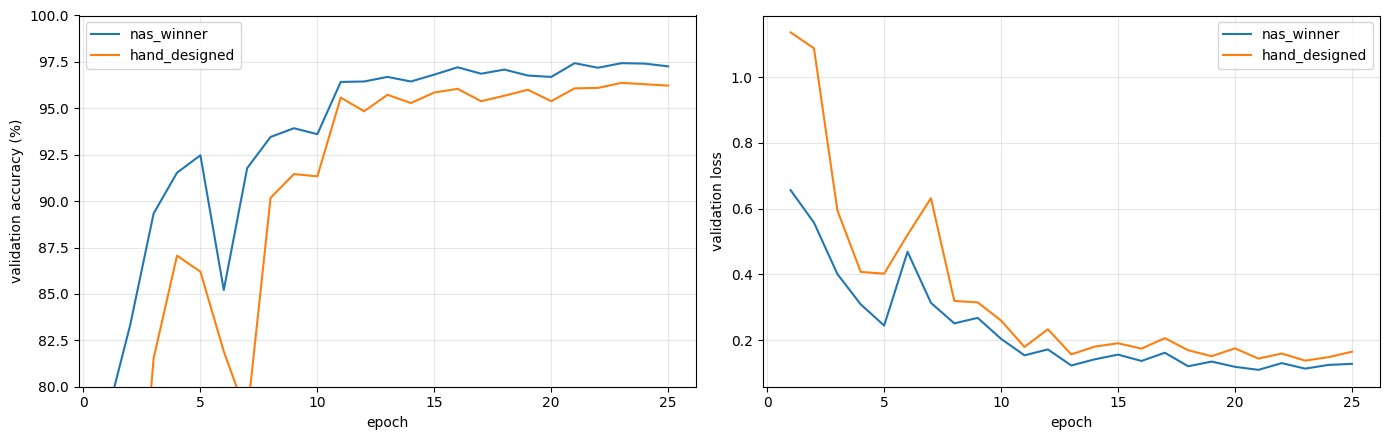

In [22]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for key, r in final.items():
    ep = range(1, n_epochs + 1)
    ax[0].plot(ep, r["history"]["val_acc"], label=key)
    ax[1].plot(ep, r["history"]["val_loss"], label=key)
ax[0].set_ylabel("validation accuracy (%)"); ax[0].set_ylim(80, 100)
ax[1].set_ylabel("validation loss")
for a in ax:
    a.set_xlabel("epoch"); a.legend(); a.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## f. Load the checkpoint of the NAS winner and test it on unseen mini-batches

k53333_w64_bn_pool_skip


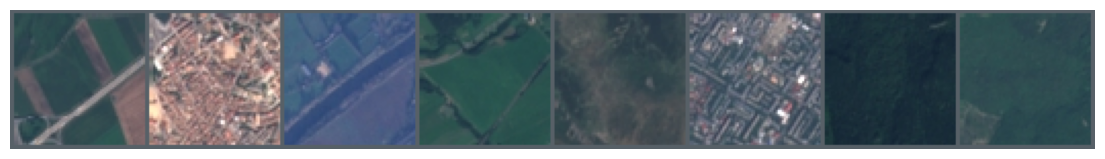

GroundTruth:  Highway | Residential | River | Pasture | HerbaceousVegetation | Residential | Forest | Forest
Predicted  :  Highway (0.96) | Residential (0.97) | River (0.80) | Pasture (0.96) | HerbaceousVegetation (0.98) | Residential (0.97) | Forest (0.98) | Forest (0.94)


In [23]:
with open(os.path.join(RES_DIR, "NB6_2_nas_results.json")) as f:
    WINNER_ARCH = json.load(f)["winner"]["arch"]
print(arch_name(WINNER_ARCH))

trainednet = SearchNet(**WINNER_ARCH)
trainednet.load_state_dict(torch.load(os.path.join(CKPT_DIR, "NB6_2_nas_winner.pth"), map_location="cpu"))
trainednet.eval()

def imshow(img):
    img = img * torch.tensor(STD).view(3, 1, 1) + torch.tensor(MEAN).view(3, 1, 1)
    npimg = img.clamp(0, 1).numpy()
    plt.imshow(np.transpose(npimg, (1, 2, 0)))
    plt.axis("off")

demo_loader = DataLoader(testset, batch_size=8, shuffle=True)
images, labels = next(iter(demo_loader))
with torch.no_grad():
    outputs = trainednet(images)
    softmax = nn.Softmax(dim=1)
    probs = softmax(outputs)
    conf, predicted = torch.max(probs, 1)

plt.figure(figsize=(14, 3))
imshow(torchvision.utils.make_grid(images, nrow=8))
plt.show()
print('GroundTruth: ', ' | '.join('%s' % classes[labels[j]] for j in range(8)))
print('Predicted  : ', ' | '.join('%s (%.2f)' % (classes[predicted[j]], conf[j]) for j in range(8)))